<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/week15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### Polynormial model

###

In [ ]:
#importing  the dataset
data= pd.read_csv("/content/drive/MyDrive/task1_polynomial_data (1).csv")
X= data.iloc[:,:-1].values
Y = data.iloc[:,1].values


In [ ]:
#creating linear regression
from sklearn.linear_model import LinearRegression #importing linear regression model from the sklearn library

#creating the Linear regression model
lin_reg = LinearRegression()#calling the model
lin_reg.fit(X, Y)#fitting the dataset to the model


LinearRegression()

In [ ]:
#creating the Polynormial model degree 2 which is used to transform the input data
#importing the Polynormial model
from sklearn.preprocessing import PolynomialFeatures
pol_reg = PolynomialFeatures(degree=2)#transforming tool
X_poly= pol_reg.fit_transform(X)


In [ ]:
#creating linear regression model 2 and fitting in the poly transformed
lin_reg2 = LinearRegression()
lin_reg2.fit(X_poly, Y)

LinearRegression()

In [ ]:
#creating the Polynormial model degree 3 which is used to transform the input data
pol_reg3 = PolynomialFeatures(degree=3)#transforming tool
X_poly3= pol_reg3.fit_transform(X)


In [ ]:
#creating linear regression model 3 and fitting in the poly transformed
lin_reg3 = LinearRegression()
lin_reg3.fit(X_poly3, Y)

LinearRegression()

In [ ]:
#creating the Polynormial model degree 4 which is used to transform the input data
pol_reg4 = PolynomialFeatures(degree=4)#transforming tool
X_poly4= pol_reg4.fit_transform(X)


In [ ]:
#creating linear regression model 3 and fitting in the poly transformed
lin_reg4 = LinearRegression()
lin_reg4.fit(X_poly4, Y)

LinearRegression()

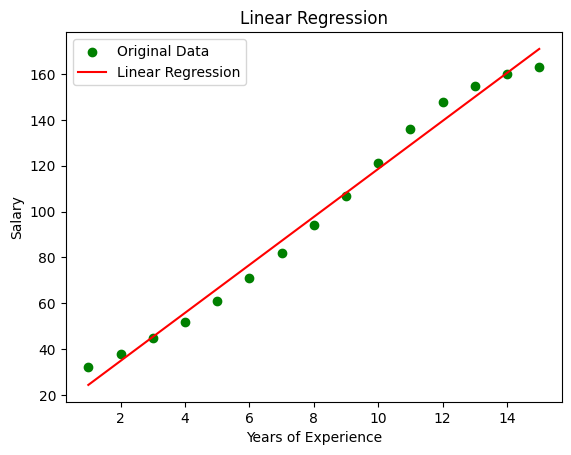

In [ ]:
#Creating Visualisations

#Regression line/curve
#Proper title and labels

X_grid = np.linspace(X.min(), X.max(), 100).reshape(-1,1)  # smoother curves for poly models

# Linear Regression
#1.Original data points
plt.scatter(X, Y, color='green', label='Original Data')
plt.plot(X, lin_reg.predict(X), color='red', label='Linear Regression')
plt.title('Linear Regression')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

### observation
Linear Regression: The red line is perfectly straight. It represents a constant rate of change between "Years of Experience" and the target variable which is the salary.


### Observation and Learning
By importing and using the Polynomial features we will be able handle situations where data does not follow a straight line. Instead of changing the model, we expand the input by adding new columns such as x to power 2 or x to power 3. This transformation allows the model to “see” curved patterns in the data. Importantly, polynomial features do not train a model; they only prepare the data.

The first linear regression model is trained using the original input feature and assumes a straight-line relationship between the input and the target. This works well when the data is roughly linear, but it struggles when the relationship is curved.

After transforming the data using polynomial features, a second linear regression model is required because the input features are now different. This model learns from the expanded features and can capture non-linear relationships, even though the learning process itself remains linear in terms of the coefficients.

In summary, the first regression fits a straight line, while the second regression fits a curve by using polynomial-expanded features. Polynomial regression is therefore a combination of feature transformation and linear regression, working together to model more complex patterns.

Different degrees give different flexibility:

Degree 2: Smooth curve, captures the overall trend nicely without overcomplicating things.

Degree 3: Can follow sharper trends, fits the data closer, but starts to risk overfitting.

Degree 4: Very flexible, fits almost every little fluctuation which is good for complex patterns, but can overfit if the dataset is small.

In [ ]:
# creating the Predictions for someone who worked for 8.5 years
pred_lin = lin_reg.predict([[8.5]])
print("Linear Regression Prediction (8.5 years):", pred_lin[0])


Linear Regression Prediction (8.5 years): 102.90416666666667


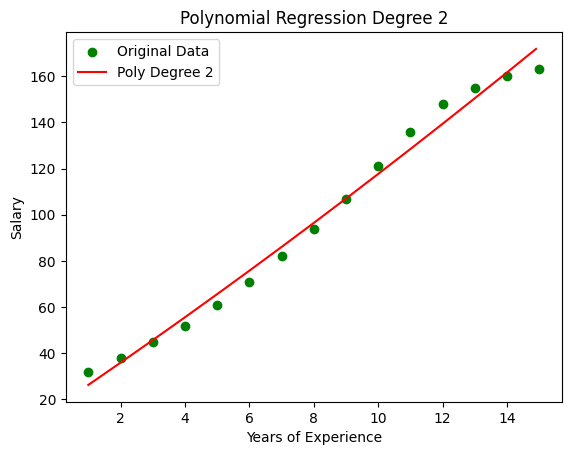

In [ ]:
# Creating smooth X grid for curve plotting
X_grid = np.arange(X.min(), X.max(), 0.1).reshape(-1, 1)

# Transforming X_grid using the SAME pol_reg object (degree 2)
X_grid_poly = pol_reg.transform(X_grid)

# Plotting original data points
plt.scatter(X, Y, color='green', label='Original Data')

# Plotting regression curve
plt.plot(X_grid, lin_reg2.predict(X_grid_poly), color='red', label='Poly Degree 2')

# Titles and labels
plt.title('Polynomial Regression Degree 2')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

### Observation
Polynomial Regression: The red line is curved. Because it is degree 2, it follows a parabolic shape that attempts to bend and follow the slight curve in the green data points.

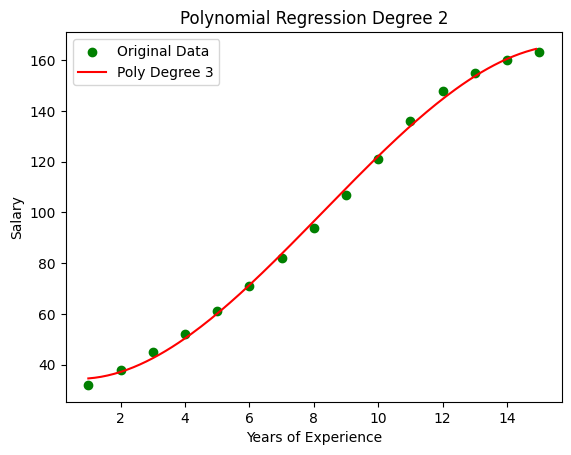

In [ ]:
# Creating smooth X grid for curve plotting
X_grid = np.arange(X.min(), X.max(), 0.1).reshape(-1, 1)

# Transforming X_grid using the SAME pol_reg object (degree 2)
X_grid_poly = pol_reg3.transform(X_grid)

# Plotting original data points
plt.scatter(X, Y, color='green', label='Original Data')

# Plotting regression curve
plt.plot(X_grid, lin_reg3.predict(X_grid_poly), color='red', label='Poly Degree 3')

# Titles and labels
plt.title('Polynomial Regression Degree 2')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

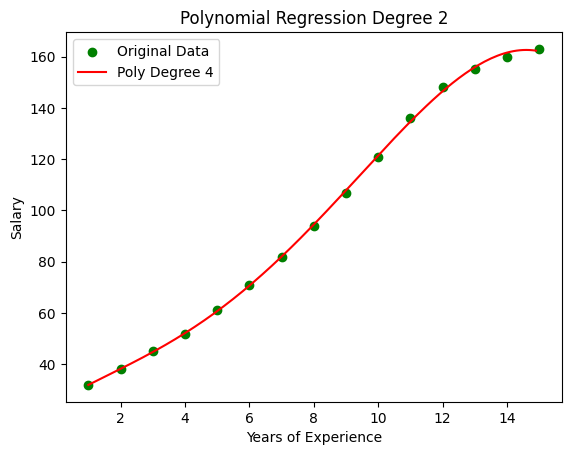

In [ ]:
# Creating smooth X grid for curve plotting
X_grid = np.arange(X.min(), X.max(), 0.1).reshape(-1, 1)

# Transforming X_grid using the SAME pol_reg object (degree 4)
X_grid_poly = pol_reg4.transform(X_grid)

# Plotting original data points
plt.scatter(X, Y, color='green', label='Original Data')

# Plotting regression curve
plt.plot(X_grid, lin_reg4.predict(X_grid_poly), color='red', label='Poly Degree 4')

# Titles and labels
plt.title('Polynomial Regression Degree 2')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()

### Observation
1. Model Complexity and Flexibility
The higher the degree, the more "flexible" the red line becomes. This allows it to change direction more frequently to hit the green data points.

Linear Regression: Completely rigid; a single straight line.
Degree 2: A simple curve (parabola). It captures the general arc but misses the finer details.
Degree 3 & 4: These introduce "S-curves" or "waves." They can bend multiple times to pass almost exactly through every single green dot.

2. The Risk of "Overfitting"
While the Degree 3 and Degree 4 lines look better fitted because they touch more dots, they introduce a common machine learning problem called Overfitting.

Linear Regression 1 & Polynomial degree 2: These models provide a "generalization." They understand the overall trend of the data.

Degrees 3 & 4: These models are becoming "obsessed" with the specific data points in the training set. Incase I added a new data point at 16 years, these complex curves might make a wild, inaccurate prediction because they are so focused on following the exact path of the existing dots.

question 2 link: https://colab.research.google.com/drive/1_DuHl9ltO9thehmk97xAz00-79fVOaBv?usp=sharing

question 3: https://colab.research.google.com/drive/1YbuK7E8vqC9nvCVm8aA5Y-LItre_ygf2?usp=sharing

Assignment 1: https://colab.research.google.com/drive/1Q02YFq6qc1iAyfVZsw48i45G-F0hcyww?usp=sharing

Assignment 2:https://colab.research.google.com/drive/1s_6iDJ4yUpWWQsyVS1tlR_169D0I2RBu?usp=sharing

assignment 3:https://colab.research.google.com/drive/10zMiLH6UvY7HT8h6Tpp9I1UM-53qjQgv?usp=sharing

project:https://colab.research.google.com/drive/1qfpdeRJ9Tlhb89D2BKCY2jU2jNPs6wwA?usp=sharing

writeup:https://medium.com/@jacinta.chege213/linear-regression-modelling-week-1-b65ed0645fc9